# Create Bubble Plot for MyoPgrd/d DEG Pathways Using Output Files from Ingenuity Pathway Analysis

In [1]:
library(data.table)
library(dplyr)
library(ggplot2)
library(svglite)

Warning message:
“package ‘data.table’ was built under R version 4.3.3”
Warning message:
“package ‘dplyr’ was built under R version 4.3.3”

Attaching package: ‘dplyr’


The following objects are masked from ‘package:data.table’:

    between, first, last


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




In [2]:
relevant_pws_MyoPgrdd <- fread("Myh11Pgr-Pathways.csv")
relevant_pws_MyoPgrdd$Category <- as.factor(relevant_pws_MyoPgrdd$Category)
relevant_pws_MyoPgrdd <- relevant_pws_MyoPgrdd %>% group_by(Category) %>% arrange(desc(zScore), .by_group = TRUE)
head(relevant_pws_MyoPgrdd, 10)

Ingenuity Canonical Pathways,Category,-log(p-value),zScore,Ratio,Molecules
<chr>,<fct>,<dbl>,<dbl>,<dbl>,<chr>
SRP-dependent cotranslational protein targeting to membrane,Cell stress,8.90,4.490731,0.209,"RPL11,RPL15,RPL27A,RPL35,RPL36AL,RPL39,RPL3L,RPL41,RPLP2,RPS11,RPS13,RPS15A,RPS21,RPS27L,RPS3,RPS6,RPS8,SEC61A1,SEC61B,SEC61G,SRP9,SRPRB,SSR1,SSR2"
Response of EIF2AK4 (GCN2) to amino acid deficiency,Cell stress,5.02,3.638034,0.165,"RPL11,RPL15,RPL27A,RPL35,RPL36AL,RPL39,RPL3L,RPL41,RPLP2,RPS11,RPS13,RPS15A,RPS21,RPS27L,RPS3,RPS6,RPS8"
Nonsense-Mediated Decay (NMD),Cell stress,4.28,3.638034,0.145,"RPL11,RPL15,RPL27A,RPL35,RPL36AL,RPL39,RPL3L,RPL41,RPLP2,RPS11,RPS13,RPS15A,RPS21,RPS27L,RPS3,RPS6,RPS8"
Cellular response to hypoxia,Cell stress,3.01,3.316625,0.147,"HIGD1A,PSMA3,PSMA6,PSMA7,PSMB10,PSMB2,PSMB3,PSMB4,PSMB6,PSMC2,PSME2"
Regulation of Apoptosis,Cell stress,3.68,3.162278,0.189,"PSMA3,PSMA6,PSMA7,PSMB10,PSMB2,PSMB3,PSMB4,PSMB6,PSMC2,PSME2"
Cachexia Signaling Pathway,Cell stress,2.93,2.828427,0.087,"ACVR2B,ADCY2,ADRB2,BCL2,CAPN6,CASP14,CASP8,CCL2,IFNG,IGF1R,IL6,MAP2K4,MAPK13,PIK3C2B,PIK3R5,PPARG,PRKAB2,PRKD1,PSMA3,PSMA6,PSMA7,PSMB10,PSMB2,PSMB3,PSMB4,PSMB6,PSMC2,PSME2,RXFP2,STAT1,STAT5A,TNF"
Microautophagy Signaling Pathway,Cell stress,5.49,2.672612,0.144,"CHMP4B,COL11A1,COL12A1,COL24A1,COL25A1,COL4A5,COL4A6,Col6a4,COL7A1,COL9A3,MAP1LC3A,PRKAB2,PSMA3,PSMA6,PSMA7,PSMB10,PSMB2,PSMB3,PSMB4,PSMB6,PSMC2,PSME2,SEC31B"
Induction of Apoptosis by HIV1,Cell stress,1.88,1.133893,0.123,"BCL2,CASP8,CYC1,CYCS,MAP2K4,NAIP,Naip1 (includes others),TNF"
Granzyme A Signaling,Cell stress,7.95,-2.828427,0.243,"GZMA,NDUFA11,NDUFA12,NDUFA13,NDUFA4,NDUFA5,NDUFA8,NDUFB1,NDUFB2,NDUFB3,NDUFB4,NDUFB7,NDUFB8,NDUFB9,NDUFS2,NDUFS8,NME1,PRF1"


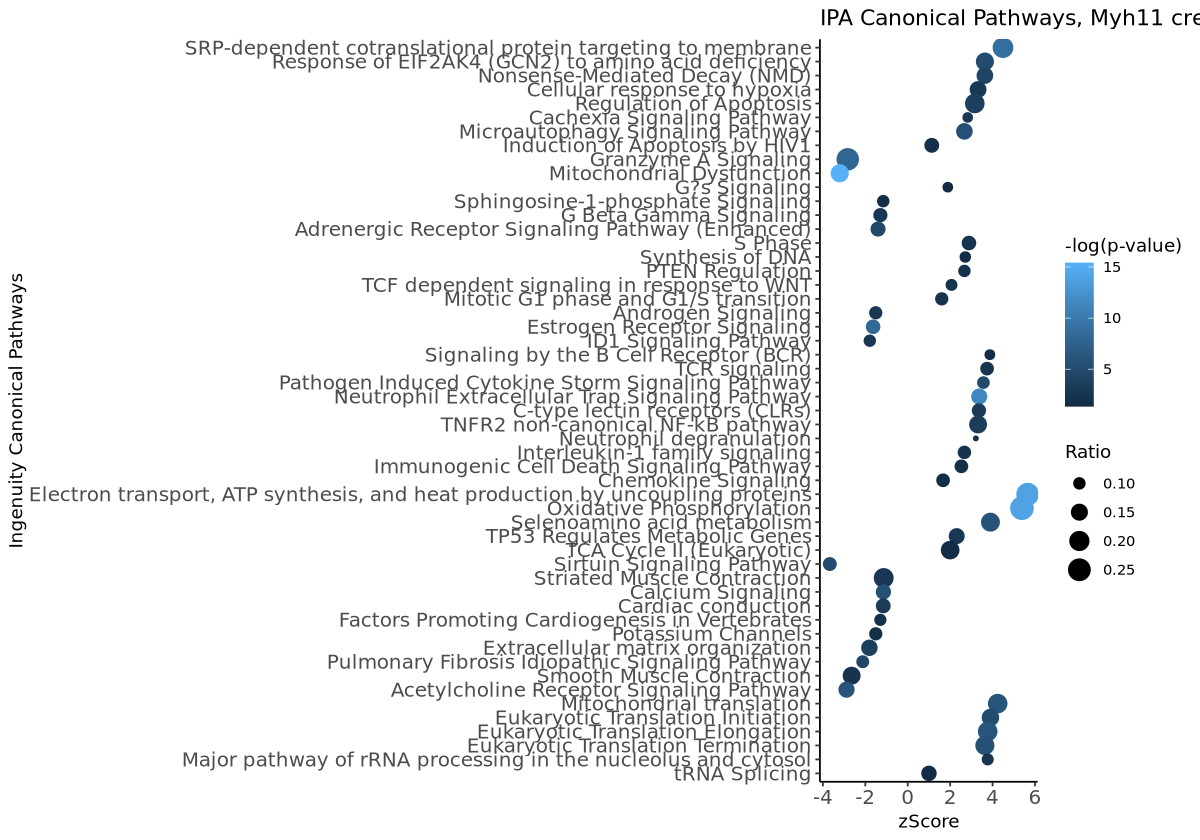

In [4]:
## Make dot plots for GO terms.

# Make the function for GO plots. See the Github link above.
# Code taken from enrichplot: https://github.com/YuLab-SMU/enrichplot/blob/devel/R/dotplot.R#L200-L207
ipa_plot <- function(ipa_table, title) {
    tmp <- ipa_table #%>% arrange(desc(Category))
    tmp[["Ingenuity Canonical Pathways"]] <- ordered(tmp[["Ingenuity Canonical Pathways"]],
                                                     levels=rev(tmp[["Ingenuity Canonical Pathways"]]))
    return(ggplot(tmp,
                  aes(y = `Ingenuity Canonical Pathways`,
                      x = zScore,
                      size = Ratio,
                      color = `-log(p-value)`)) + geom_point() + theme_bw() +  theme(axis.line = element_line(colour = "black"),
    panel.grid.major = element_blank(),
    panel.grid.minor = element_blank(),
    panel.border = element_blank(),
    panel.background = element_blank(),
                                                                                    axis.text=element_text(size=12)) +
                   ggtitle(title))
}


saved <- options(repr.plot.width = 10)
ipa_plot(relevant_pws_MyoPgrdd, "IPA Canonical Pathways, Myh11 cre/+ Pgr f/f")
options(saved)

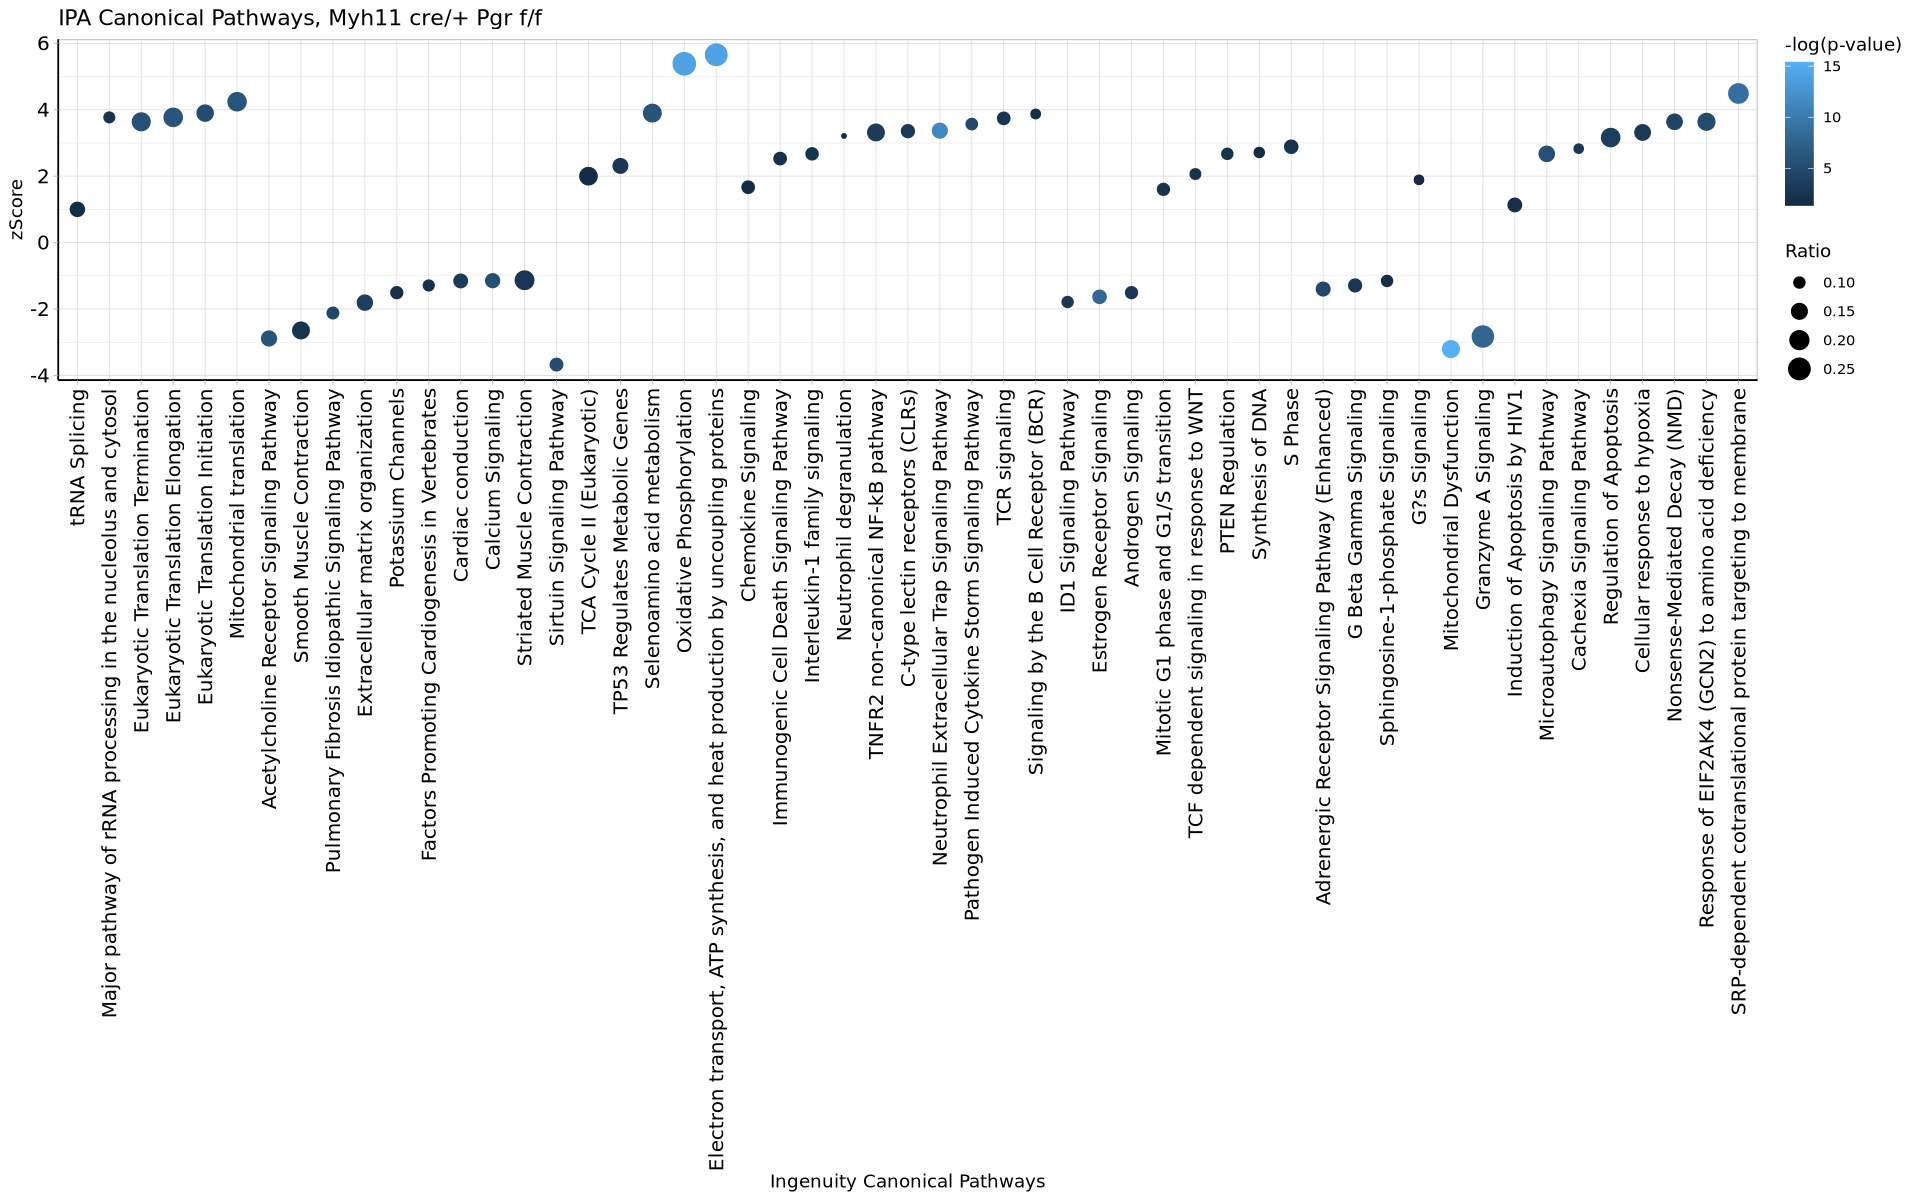

In [11]:
# Modify the layout and theme

ipa_plot <- function(ipa_table, title) {
    tmp <- ipa_table #%>% arrange(desc(Category))
    tmp[["Ingenuity Canonical Pathways"]] <- ordered(tmp[["Ingenuity Canonical Pathways"]],
                                                     levels=rev(tmp[["Ingenuity Canonical Pathways"]]))
    return(ggplot(tmp,
                  aes(y = zScore,
                      x = `Ingenuity Canonical Pathways`,
                      size = Ratio,
                      color = `-log(p-value)`)) + geom_point() + theme_light() +  theme(axis.line = element_line(colour = "black"),
    #panel.grid.major = element_blank(),
    #panel.grid.minor = element_blank(),
    #panel.border = element_blank(),
    #panel.background = element_blank(),
                axis.text.x=element_text(angle=90, hjust=1, vjust=0.5),
                axis.text=element_text(size=12, color="black")) +
                   ggtitle(title))
}


saved <- options(repr.plot.width = 16, repr.plot.height = 10)
ipa_plot(relevant_pws_MyoPgrdd, "IPA Canonical Pathways, Myh11 cre/+ Pgr f/f")
options(saved)

In [12]:
# Save plot as SVG

my_plot <- ipa_plot(relevant_pws_MyoPgrdd, "IPA Canonical Pathways, Myh11 cre/+ Pgr f/f")

    
ggsave(filename = "251205_MyoPgrdd_IPA.svg", plot = my_plot, 
           width = 14, height = 10, units = "in") 

In [13]:
sessionInfo()

R version 4.3.1 (2023-06-16)
Platform: x86_64-conda-linux-gnu (64-bit)
Running under: Rocky Linux 8.10 (Green Obsidian)

Matrix products: default
BLAS/LAPACK: /ddn/gs1/home/marquardtrm/miniforge3/envs/r431/lib/libopenblasp-r0.3.30.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=en_US.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=en_US.UTF-8        LC_COLLATE=en_US.UTF-8    
 [5] LC_MONETARY=en_US.UTF-8    LC_MESSAGES=en_US.UTF-8   
 [7] LC_PAPER=en_US.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=en_US.UTF-8 LC_IDENTIFICATION=C       

time zone: America/New_York
tzcode source: system (glibc)

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
[1] svglite_2.2.2     ggplot2_4.0.1     dplyr_1.1.4       data.table_1.17.8

loaded via a namespace (and not attached):
 [1] crayon_1.5.3       vctrs_0.6.5        cli_3.6.5          rlang_1.1.6  